# Modelo supervisado de peso al nacer — con datos reales
### Fetal Medical Bolivia · Proyecto Integrador 2026 · UNIFRANZ

**Qué hace:** predice el **peso al nacer** de un bebé (regresión) y detecta si
va a nacer con **bajo peso**, menos de 2.500 g (clasificación).

**Tipo de modelo:** aprendizaje **supervisado**. Aprende de nacimientos en los
que ya se conoce el resultado y aplica lo aprendido a casos nuevos.

**Los datos son reales:** 1.000 nacimientos de los registros de natalidad de
Estados Unidos de 2014 (CDC), publicados por OpenIntro para docencia. Están en
`datos/nacimientos_reales_2014.xlsx`.

| Sección | Contenido |
|---|---|
| **Antes de empezar** | Qué es Hadlock |
| Paso 1 | Importación de librerías |
| Paso 2 | Carga de datos |
| Paso 3 | Exploración de datos |
| Paso 4 | Definición de variables de entrada (X) y objetivo (y) |
| Paso 5 | Crear y entrenar el modelo |
| Paso 6 | Hacer predicciones |
| Paso 7 | Evaluar el modelo: métricas, R², ROC, matriz de confusión, gráficas, y cómo implementarlo |

---
## Antes de empezar: ¿qué es Hadlock?

**Hadlock** es el apellido de **Frank P. Hadlock**, un radiólogo
estadounidense. En 1985 publicó, con su equipo, una **fórmula para estimar
cuánto pesa un bebé dentro del útero** a partir de medidas que se toman en la
ecografía. Es la fórmula más usada en el mundo para esto, y es la que usa el
sistema Fetal Medical Bolivia.

### Qué mide

En la ecografía se miden cuatro cosas del bebé:

| Medida | Sigla | Qué es |
|---|---|---|
| Diámetro biparietal | DBP | El ancho de la cabeza |
| Circunferencia cefálica | CC | El contorno de la cabeza |
| Circunferencia abdominal | CA | El contorno del abdomen. **Es la que más pesa**: refleja la grasa y el hígado |
| Longitud del fémur | LF | El largo del hueso del muslo |

### La fórmula (Hadlock 1985, cuatro medidas)

$$\log_{10}(\text{peso en gramos}) = 1{,}3596 - 0{,}00386 \cdot CA \cdot LF + 0{,}0064 \cdot CC + 0{,}00061 \cdot DBP \cdot CA + 0{,}0425 \cdot CA + 0{,}174 \cdot LF$$

con **todas las medidas en centímetros**. Su error declarado es de **±15%**.

### Las dos cosas que hizo Hadlock

1. **La fórmula (1985):** de las medidas de la ecografía al peso de hoy.
2. **La curva de crecimiento (1991):** cuánto pesa un bebé normal en cada
   semana del embarazo, con sus percentiles 10, 50 y 90. Sirve para saber si
   un bebé es pequeño, normal o grande **para su edad**.

### Lo que se descubrió en el sistema

El sistema guarda las medidas en **milímetros**, pero la fórmula está publicada
en **centímetros**, y nadie convertía. Resultado: la fórmula devolvía **0 g en
el 62% de las ecografías** y disparates en el resto, como 13 kilos para un bebé
de 12 semanas. Ya está corregido. La celda de abajo lo muestra con un ejemplo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def hadlock_1985(dbp_mm, cc_mm, ca_mm, lf_mm):
    # Peso fetal estimado en gramos. Recibe MILÍMETROS y los pasa a centímetros,
    # que es como está publicada la fórmula.
    dbp, cc, ca, lf = dbp_mm / 10, cc_mm / 10, ca_mm / 10, lf_mm / 10
    log_peso = (1.3596 - 0.00386 * ca * lf + 0.0064 * cc
                + 0.00061 * dbp * ca + 0.0425 * ca + 0.174 * lf)
    return 10 ** log_peso


def hadlock_1985_con_el_error(dbp_mm, cc_mm, ca_mm, lf_mm):
    # Lo que hacía el sistema antes: meter milímetros en una fórmula de centímetros.
    log_peso = (1.3596 - 0.00386 * ca_mm * lf_mm + 0.0064 * cc_mm
                + 0.00061 * dbp_mm * ca_mm + 0.0425 * ca_mm + 0.174 * lf_mm)
    return 10 ** log_peso


# Un bebé a término: DBP 90 mm, CC 320 mm, CA 330 mm, LF 70 mm
print(f"Bien calculado (mm -> cm):  {hadlock_1985(90, 320, 330, 70):,.0f} g".replace(",", "."))
print(f"Con el error del sistema:   {hadlock_1985_con_el_error(90, 320, 330, 70):.1e} g  ->  0 g")

Bien calculado (mm -> cm):  2.981 g
Con el error del sistema:   3.7e-42 g  ->  0 g


### La curva de Hadlock 1991

Peso fetal por semana de embarazo. La línea del centro es el **percentil 50**
(el bebé típico); la banda va del **percentil 10** al **90**. Un bebé por debajo
de la banda es pequeño para su edad; por encima, grande.

**En este notebook la curva es el rival del modelo.** Los datos reales no
tienen medidas de ecografía, así que no se puede aplicar la fórmula de cuatro
medidas; lo que sí se puede es decir *«a las 39 semanas, Hadlock espera 3.435 g»*
y comparar eso con lo que predice el modelo.

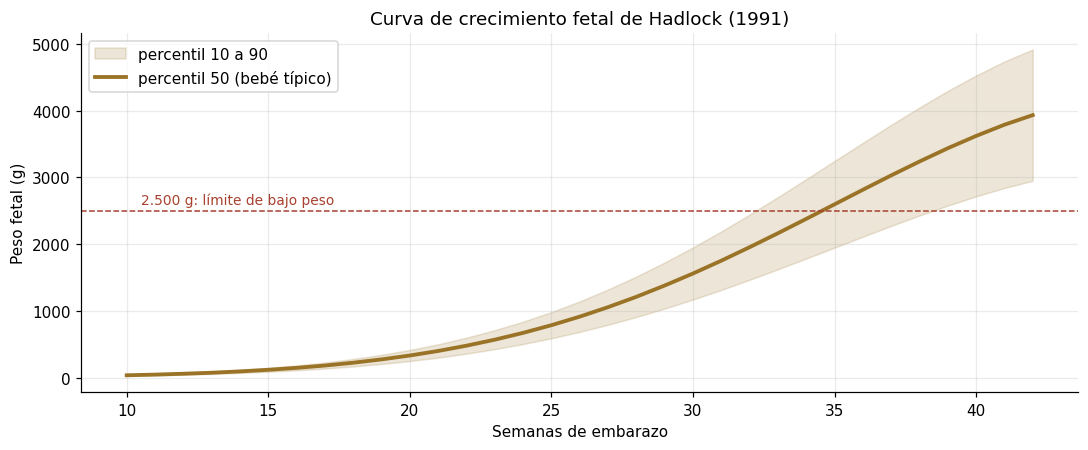

In [2]:
# Hadlock FP, Harrist RB, Martinez-Poyer J. In utero analysis of fetal growth:
# a sonographic weight standard. Radiology 1991;181:129-133.
# semana: (percentil 10, percentil 50, percentil 90) en gramos
HADLOCK_1991 = {
    10: (26, 35, 44), 11: (34, 45, 56), 12: (43, 58, 73), 13: (55, 73, 91),
    14: (70, 93, 116), 15: (88, 117, 146), 16: (110, 146, 183), 17: (136, 181, 226),
    18: (167, 223, 279), 19: (205, 273, 341), 20: (248, 331, 414), 21: (299, 399, 499),
    22: (359, 478, 598), 23: (426, 568, 710), 24: (503, 670, 838), 25: (589, 785, 981),
    26: (685, 913, 1141), 27: (791, 1055, 1319), 28: (908, 1210, 1513),
    29: (1034, 1379, 1724), 30: (1169, 1559, 1949), 31: (1313, 1751, 2189),
    32: (1465, 1953, 2441), 33: (1622, 2162, 2703), 34: (1783, 2377, 2971),
    35: (1946, 2595, 3244), 36: (2110, 2813, 3516), 37: (2271, 3028, 3785),
    38: (2427, 3236, 4045), 39: (2576, 3435, 4294), 40: (2714, 3619, 4524),
    41: (2839, 3787, 4734), 42: (2948, 3931, 4914),
}


def hadlock_curva(semanas):
    # Peso típico (percentil 50) para esa semana. Fuera de 10-42 se usa el extremo.
    s = int(np.clip(round(semanas), 10, 42))
    return HADLOCK_1991[s][1]


AZUL, OCRE, ROJO, VERDE, GRIS = "#2e5b86", "#9a7327", "#a8412f", "#2b7656", "#9aa4a8"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

sem = sorted(HADLOCK_1991)
p10, p50, p90 = zip(*(HADLOCK_1991[s] for s in sem))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.fill_between(sem, p10, p90, color=OCRE, alpha=0.18, label="percentil 10 a 90")
ax.plot(sem, p50, color=OCRE, lw=2.5, label="percentil 50 (bebé típico)")
ax.axhline(2500, color=ROJO, ls="--", lw=1)
ax.text(10.5, 2600, "2.500 g: límite de bajo peso", color=ROJO, fontsize=9)
ax.set_title("Curva de crecimiento fetal de Hadlock (1991)")
ax.set_xlabel("Semanas de embarazo")
ax.set_ylabel("Peso fetal (g)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

---
## Paso 1: Importación de librerías

- **pandas** y **numpy**: manejar la tabla y hacer cuentas.
- **matplotlib**: las gráficas.
- **scikit-learn**: los modelos y las métricas.

La **semilla** (`2026`) hace que cada ejecución dé exactamente los mismos
resultados.

In [3]:
# Paso 1: Importación de librerías
import time
import warnings
from pathlib import Path

import pandas as pd
import sklearn
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.base import clone
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             roc_curve, roc_auc_score, confusion_matrix)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEMILLA = 2026
np.random.seed(SEMILLA)
print(f"pandas {pd.__version__}  ·  numpy {np.__version__}  ·  scikit-learn {sklearn.__version__}")

pandas 2.3.3  ·  numpy 2.4.6  ·  scikit-learn 1.8.0


---
## Paso 2: Carga de datos

`datos/nacimientos_reales_2014.xlsx` tiene tres hojas:

| Hoja | Contenido |
|---|---|
| **Nacimientos** | Los 1.000 nacimientos reales, en español y en gramos |
| **Diccionario** | Qué significa cada columna y si entra al modelo |
| **Fuente** | De dónde vienen los datos |

En la carpeta `datos/` también está `muestra_simulada_5000.xlsx`, la muestra
simulada de 5.000 casos del sistema, **con medidas de ecografía**. Se usó en el
notebook del sistema; aquí se deja como referencia.

In [4]:
# Paso 2: Carga de datos
RUTA = Path("datos/nacimientos_reales_2014.xlsx")
df = pd.read_excel(RUTA, sheet_name="Nacimientos")
diccionario = pd.read_excel(RUTA, sheet_name="Diccionario")
fuente = pd.read_excel(RUTA, sheet_name="Fuente")

print(f"{len(df):,} nacimientos reales  ·  {df.shape[1]} columnas".replace(",", "."))
df.head(8)

1.000 nacimientos reales  ·  13 columnas


,id,semanas_gestacion,edad_madre,edad_padre,controles_prenatales,aumento_peso_madre_kg,fumadora,sexo_bebe,prematuro,casada,madre_blanca,peso_nacimiento_g,bajo_peso
0,1,37,34,34.0,14.0,12.7,0.0,masculino,0,1,1,3157,0
1,2,41,31,36.0,12.0,18.6,0.0,femenino,0,1,1,4019,0
2,3,37,36,37.0,10.0,12.7,0.0,femenino,0,1,0,3406,0
3,4,38,16,NaN,NaN,13.2,0.0,masculino,0,0,1,2808,0
4,5,36,31,32.0,12.0,21.8,0.0,femenino,1,1,1,3062,0
5,6,39,26,32.0,14.0,20.4,0.0,femenino,0,1,1,3035,0
6,7,36,36,37.0,10.0,9.1,0.0,femenino,1,1,1,2781,0
7,8,40,24,29.0,13.0,29.5,0.0,masculino,0,0,1,3057,0


In [5]:
pd.set_option("display.max_colwidth", 90)
fuente

,campo,detalle
0,Qué son,"Nacimientos reales, elegidos al azar"
1,Origen,"Registros de natalidad de Estados Unidos, año 2014 (CDC)"
2,Publicado por,"OpenIntro, conjunto de datos «births14», de uso libre para docencia"
3,Dirección,https://www.openintro.org/data/index.php?data=births14
4,Tamaño,1000 nacimientos
5,Qué NO tienen,Medidas de ecografía (no se puede aplicar Hadlock de 4 medidas)
6,Aviso,Población de EE. UU.: los resultados no se trasladan tal cual a Bolivia


In [6]:
diccionario

,columna,descripcion,unidad,entra_al_modelo
0,id,Número de registro,—,no: identificador
1,semanas_gestacion,Semanas de embarazo al nacer,semanas,SÍ
2,edad_madre,Edad de la madre,años,SÍ
3,edad_padre,Edad del padre (vacío si no se registró),años,SÍ
4,controles_prenatales,Visitas médicas durante el embarazo,n.º,SÍ
5,aumento_peso_madre_kg,Kilos que ganó la madre en el embarazo,kg,SÍ
6,fumadora,La madre fumaba durante el embarazo,0/1,SÍ
7,sexo_bebe,Sexo del bebé,texto,SÍ (como 1 = masculino)
8,prematuro,Nació antes de las 37 semanas,0/1,no: se deduce de las semanas
9,casada,Estado civil de la madre,0/1,"no: variable social, no clínica"


---
## Paso 3: Exploración de datos

Antes de entrenar hay que mirar: qué falta, cómo se reparten los casos, y si
hay una relación real que aprender.

### 3.1 Valores que faltan

In [7]:
faltan = df.isna().sum()
tabla_faltan = pd.DataFrame({"faltan": faltan, "% que falta": (faltan / len(df) * 100).round(1)})
tabla_faltan[tabla_faltan["faltan"] > 0]

,faltan,% que falta
edad_padre,114,11.4
controles_prenatales,56,5.6
aumento_peso_madre_kg,42,4.2
fumadora,19,1.9


Los datos reales **tienen huecos**: la edad del padre falta en un 11% de los
casos, y los controles prenatales y el aumento de peso en un 4-6%. No se borran
esas filas: se rellenan con la mediana **dentro del modelo** (paso 5), usando
solo los datos de entrenamiento.

### 3.2 Estadísticas

In [8]:
df[["semanas_gestacion", "edad_madre", "controles_prenatales",
    "aumento_peso_madre_kg", "peso_nacimiento_g"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
semanas_gestacion,1000.0,38.7,2.6,21.0,38.0,39.0,40.0,46.0
edad_madre,1000.0,28.4,5.8,14.0,24.0,28.0,33.0,47.0
controles_prenatales,944.0,11.4,4.1,0.0,9.0,12.0,14.0,30.0
aumento_peso_madre_kg,958.0,13.8,6.9,0.0,9.1,13.6,17.2,44.5
peso_nacimiento_g,1000.0,3265.1,592.7,340.0,2968.8,3316.0,3629.0,4817.0


### 3.3 Cuántos bebés nacen con bajo peso

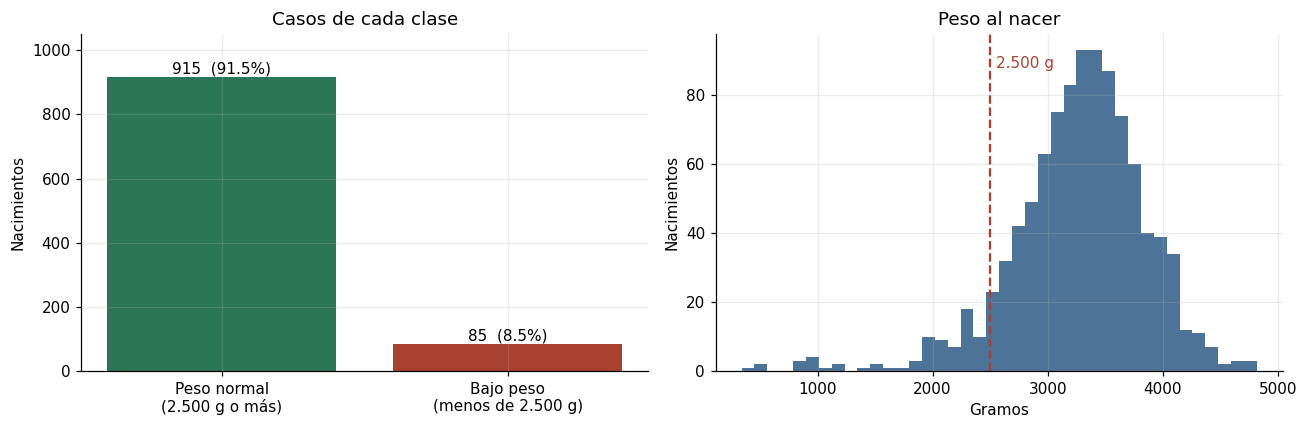

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))

n_bajo = int(df["bajo_peso"].sum())
a1.bar(["Peso normal\n(2.500 g o más)", "Bajo peso\n(menos de 2.500 g)"],
       [len(df) - n_bajo, n_bajo], color=[VERDE, ROJO])
for i, n in enumerate([len(df) - n_bajo, n_bajo]):
    a1.text(i, n + 12, f"{n}  ({n / len(df):.1%})", ha="center")
a1.set_title("Casos de cada clase")
a1.set_ylabel("Nacimientos")
a1.set_ylim(0, len(df) * 1.05)

a2.hist(df["peso_nacimiento_g"], bins=40, color=AZUL, alpha=0.85)
a2.axvline(2500, color=ROJO, ls="--")
a2.text(2550, a2.get_ylim()[1] * 0.9, "2.500 g", color=ROJO)
a2.set_title("Peso al nacer")
a2.set_xlabel("Gramos")
a2.set_ylabel("Nacimientos")
plt.tight_layout()
plt.show()

**Solo el 8,5% nace con bajo peso.** Es lo que pasa en la realidad y es un reto:
un modelo que dijera siempre «peso normal» acertaría el 91,5% de las veces **y
no detectaría a ningún bebé en riesgo**. Por eso en el paso 7 la medida que
importa es cuántos bebés de bajo peso se detectan: los **verdaderos
positivos**.

### 3.4 Los datos reales frente a la curva de Hadlock

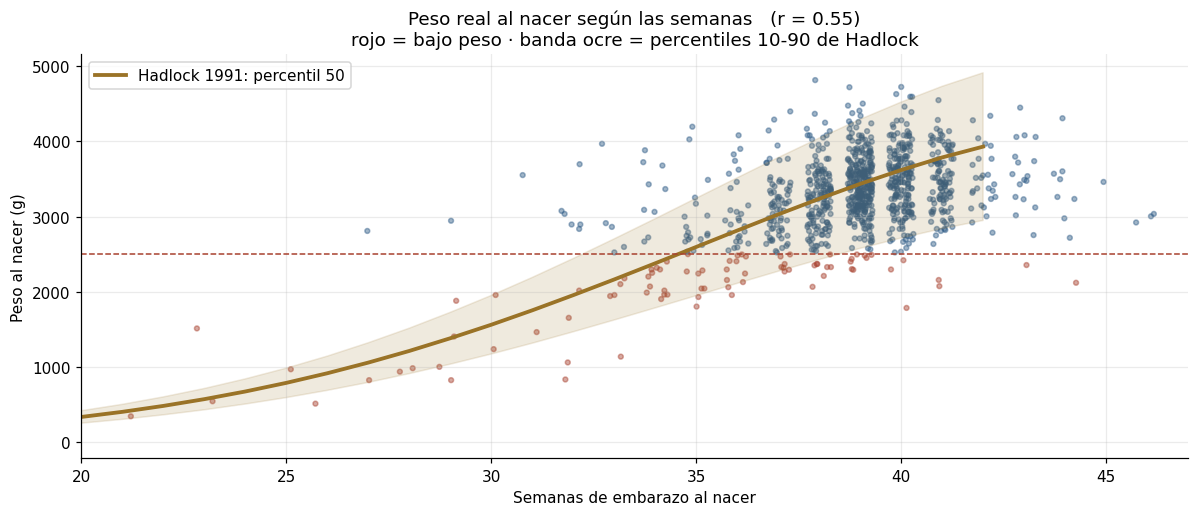

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.8))
colores = np.where(df["bajo_peso"] == 1, ROJO, AZUL)
ax.scatter(df["semanas_gestacion"] + np.random.uniform(-0.3, 0.3, len(df)),
           df["peso_nacimiento_g"], s=10, alpha=0.45, c=colores)
ax.fill_between(sem, p10, p90, color=OCRE, alpha=0.15)
ax.plot(sem, p50, color=OCRE, lw=2.5, label="Hadlock 1991: percentil 50")
ax.axhline(2500, color=ROJO, ls="--", lw=1)
r = df["semanas_gestacion"].corr(df["peso_nacimiento_g"])
ax.set_title(f"Peso real al nacer según las semanas   (r = {r:.2f})\n"
             "rojo = bajo peso · banda ocre = percentiles 10-90 de Hadlock")
ax.set_xlabel("Semanas de embarazo al nacer")
ax.set_ylabel("Peso al nacer (g)")
ax.set_xlim(20, 47)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Casi todos los bebés de bajo peso (en rojo) **nacieron antes de tiempo**. Las
semanas de embarazo son la pista más fuerte. La curva de Hadlock sigue bien la
nube de puntos reales, aunque la dispersión real es grande: dos bebés de 39
semanas pueden pesar 2.600 g y 4.300 g.

### 3.5 Qué se relaciona con el peso

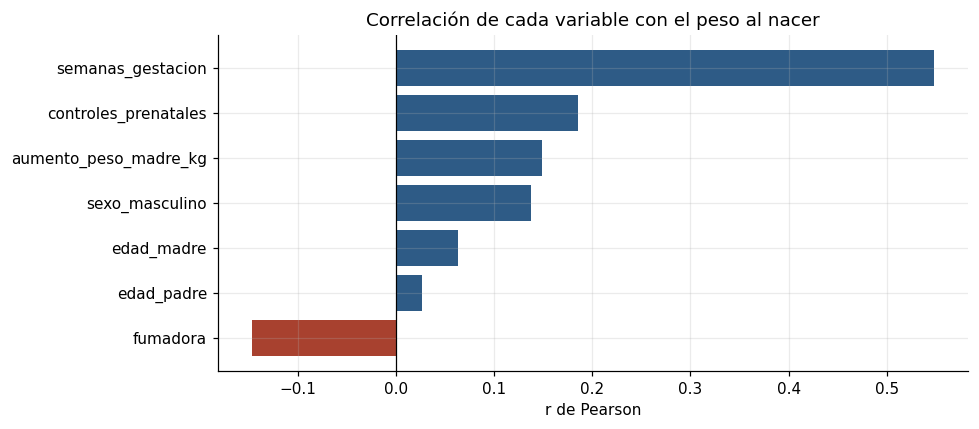

In [11]:
candidatas = ["semanas_gestacion", "edad_madre", "edad_padre", "controles_prenatales",
              "aumento_peso_madre_kg", "fumadora"]
aux = df[candidatas + ["peso_nacimiento_g"]].copy()
aux["sexo_masculino"] = (df["sexo_bebe"] == "masculino").astype(int)
corr = aux.corr()["peso_nacimiento_g"].drop("peso_nacimiento_g").sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(corr.index, corr.values, color=[AZUL if v > 0 else ROJO for v in corr.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlación de cada variable con el peso al nacer")
ax.set_xlabel("r de Pearson")
plt.tight_layout()
plt.show()

---
## Paso 4: Definición de variables de entrada (X) y objetivo (y)

- **X**: las 7 variables que se conocen antes del parto.
- **y** tiene dos versiones:
  - `peso_nacimiento_g` para la **regresión** (cuántos gramos).
  - `bajo_peso` para la **clasificación** (¿menos de 2.500 g, sí o no?).

| Columna que NO entra | Por qué |
|---|---|
| `peso_nacimiento_g`, `bajo_peso` | Son las respuestas |
| `prematuro` | Se deduce de las semanas: sería repetir la misma información |
| `casada` | Es una variable social, no clínica |
| `madre_blanca` | El origen étnico de EE. UU. no se traslada a Bolivia |

Se separa un **25% para prueba**, que el modelo no ve al aprender. La separación
es **estratificada**: el 8,5% de bajo peso queda igual en los dos grupos.

In [12]:
# Paso 4: Definición de variables de entrada (X) y objetivo (y)
df["sexo_masculino"] = (df["sexo_bebe"] == "masculino").astype(int)

ENTRADAS = ["semanas_gestacion", "edad_madre", "edad_padre", "controles_prenatales",
            "aumento_peso_madre_kg", "fumadora", "sexo_masculino"]

X = df[ENTRADAS]
y_peso = df["peso_nacimiento_g"]      # regresión
y_bajo = df["bajo_peso"]              # clasificación

X_ent, X_pru, yp_ent, yp_pru, yb_ent, yb_pru = train_test_split(
    X, y_peso, y_bajo, test_size=0.25, random_state=SEMILLA, stratify=y_bajo,
)

print(f"Entrenamiento: {len(X_ent)} nacimientos, {int(yb_ent.sum())} con bajo peso ({yb_ent.mean():.1%})")
print(f"Prueba:        {len(X_pru)} nacimientos, {int(yb_pru.sum())} con bajo peso ({yb_pru.mean():.1%})")

Entrenamiento: 750 nacimientos, 64 con bajo peso (8.5%)
Prueba:        250 nacimientos, 21 con bajo peso (8.4%)


---
## Paso 5: Crear y entrenar el modelo

### 5.1 Regresión: cuántos gramos

Se entrenan tres modelos para compararlos:

| Modelo | Cómo funciona |
|---|---|
| **Ridge** | Una suma ponderada de las variables. Cada una aporta unos gramos. |
| **Random Forest** | 300 árboles de decisión que promedian sus respuestas. |
| **Gradient Boosting** | Árboles en cadena; cada uno corrige al anterior. |

Cada modelo va dentro de un **pipeline**: primero rellena los huecos con la
mediana del entrenamiento, luego pone las variables en la misma escala, y luego
aprende. `.fit()` es el momento en que aprende.

In [13]:
# Paso 5: Crear y entrenar el modelo
regresores = {
    "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEMILLA, n_jobs=1),
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=20,
        l2_regularization=1.0, random_state=SEMILLA,
    ),
}
for nombre, m in regresores.items():
    t = time.perf_counter()
    m.fit(X_ent, yp_ent)
    print(f"{nombre:<18} entrenado en {(time.perf_counter() - t) * 1000:6.0f} ms")

Ridge              entrenado en      4 ms


Random Forest      entrenado en    388 ms


Gradient Boosting  entrenado en   1631 ms


### 5.2 Clasificación: ¿bajo peso, sí o no?

Se usa una **regresión logística**: en vez de gramos, da una **probabilidad**
de 0 a 1 de que el bebé nazca con bajo peso.

**Cómo se consigue que la mayoría sean verdaderos positivos: con el umbral.**
Como solo el 8,5% de los bebés nace con bajo peso, casi ninguno llega al 50% de
probabilidad, y con el umbral habitual del 50% la alerta no saltaría casi
nunca. Por eso se elige el umbral más alto que detecte **al menos el 85%** de
los casos de bajo peso. Se elige usando **solo los datos de entrenamiento**, para
que la prueba siga siendo honesta.

Se usa una regresión logística **sin reponderar las clases**. Así la
probabilidad que da es una probabilidad de verdad: si dice 10%, de cada 100
bebés así, unos 10 nacen con bajo peso. (Reponderar las clases da el mismo
orden, pero infla todas las probabilidades y dejan de poder leerse como tales.)

Detectar más casos tiene un precio: **más falsas alarmas**. En bajo peso se
acepta, porque dejar pasar a un bebé en riesgo cuesta mucho más que revisar a
uno sano. El paso 7 muestra cuántas.

In [14]:
SENSIBILIDAD_OBJETIVO = 0.85

clasificador = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(),
    LogisticRegression(max_iter=1000),
)


def elegir_umbral(X_e, y_e, objetivo=SENSIBILIDAD_OBJETIVO):
    # El umbral más alto que detecta al menos `objetivo` de los casos de bajo
    # peso, estimado con validación cruzada SOLO sobre el entrenamiento.
    prob = cross_val_predict(clone(clasificador), X_e, y_e, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA),
                             method="predict_proba")[:, 1]
    positivos = np.sort(prob[np.asarray(y_e) == 1])
    indice = int(np.floor((1 - objetivo) * len(positivos)))
    return float(positivos[indice])


umbral = elegir_umbral(X_ent, yb_ent)
clasificador.fit(X_ent, yb_ent)
print(f"Umbral de alerta elegido: {umbral:.3f}")
print(f"(se da la alerta de bajo peso si la probabilidad supera {umbral:.1%})")

Umbral de alerta elegido: 0.048
(se da la alerta de bajo peso si la probabilidad supera 4.8%)


### 5.3 Qué aprendió el modelo

In [15]:
coef_ridge = pd.Series(regresores["Ridge"][-1].coef_, index=ENTRADAS)
coef_log = pd.Series(clasificador[-1].coef_[0], index=ENTRADAS)
pd.DataFrame({
    "Ridge: gramos por desviación típica": coef_ridge.round(0).astype(int),
    "Logística: efecto sobre el riesgo de bajo peso": np.where(
        coef_log > 0, "lo SUBE", "lo BAJA"),
    "fuerza (coeficiente)": coef_log.round(2),
}).sort_values("Ridge: gramos por desviación típica", key=abs, ascending=False)

,Ridge: gramos por desviación típica,Logística: efecto sobre el riesgo de bajo peso,fuerza (coeficiente)
semanas_gestacion,326,lo BAJA,-1.28
sexo_masculino,76,lo BAJA,-0.11
aumento_peso_madre_kg,64,lo BAJA,-0.06
fumadora,-53,lo SUBE,0.42
edad_madre,39,lo SUBE,0.32
controles_prenatales,31,lo BAJA,-0.15
edad_padre,3,lo SUBE,0.09


Se lee así: las **semanas de embarazo** son, con diferencia, lo que más pesa:
unos 330 g por cada desviación típica, que son unas 2,6 semanas, o sea **unos
125 g por semana**. **Fumar resta peso y sube el riesgo** de bajo peso. Es lo que
dice la literatura médica, y el modelo lo encontró a partir de los datos.

---
## Paso 6: Hacer predicciones

Se aplican los modelos a los 250 bebés de prueba, que no vieron al aprender.

In [16]:
# Paso 6: Hacer predicciones
pred_peso = {n: m.predict(X_pru) for n, m in regresores.items()}
pred_peso["Curva de Hadlock"] = X_pru["semanas_gestacion"].map(hadlock_curva).to_numpy()
pred_peso["Mediana constante"] = np.full(len(yp_pru), yp_ent.median())

prob_bajo = clasificador.predict_proba(X_pru)[:, 1]
alerta = (prob_bajo >= umbral).astype(int)

pd.DataFrame({
    "semanas": X_pru["semanas_gestacion"].values,
    "peso real (g)": yp_pru.values,
    "Ridge (g)": pred_peso["Ridge"].round(0).astype(int),
    "Hadlock (g)": pred_peso["Curva de Hadlock"],
    "prob. bajo peso": np.round(prob_bajo, 2),
    "¿alerta?": np.where(alerta == 1, "SÍ", "no"),
    "¿era bajo peso?": np.where(yb_pru.values == 1, "SÍ", "no"),
}).head(15)

,semanas,peso real (g),Ridge (g),Hadlock (g),prob. bajo peso,¿alerta?,¿era bajo peso?
0,39,3420,3516,3435,0.06,SÍ,no
1,40,3343,3363,3619,0.02,no,no
2,40,3769,3391,3619,0.03,no,no
3,36,2667,2868,2813,0.12,SÍ,no
4,43,3719,3918,3931,0.00,no,no
5,41,2835,3766,3787,0.01,no,no
6,36,2667,2987,2813,0.13,SÍ,no
7,39,3289,3303,3435,0.03,no,no
8,39,3384,3209,3435,0.17,SÍ,no
9,44,2717,3825,3931,0.01,no,no


### 6.1 Un caso de consulta

Una madre de 24 años, fumadora, con 8 controles prenatales y que ha ganado 9 kg.
**¿Qué pasa según cuándo nazca el bebé?**

In [17]:
consulta = pd.DataFrame([{
    "semanas_gestacion": s, "edad_madre": 24, "edad_padre": 26,
    "controles_prenatales": 8, "aumento_peso_madre_kg": 9.0,
    "fumadora": 1, "sexo_masculino": 0,
} for s in [33, 35, 37, 39, 41]])[ENTRADAS]

p = clasificador.predict_proba(consulta)[:, 1]
pd.DataFrame({
    "si nace a las": [f"{s} semanas" for s in consulta["semanas_gestacion"]],
    "Ridge (g)": regresores["Ridge"].predict(consulta).round(0).astype(int),
    "Random Forest (g)": regresores["Random Forest"].predict(consulta).round(0).astype(int),
    "Hadlock (g)": consulta["semanas_gestacion"].map(hadlock_curva),
    "prob. bajo peso": [f"{v:.0%}" for v in p],
    "alerta": np.where(p >= umbral, "SÍ", "no"),
})

,si nace a las,Ridge (g),Random Forest (g),Hadlock (g),prob. bajo peso,alerta
0,33 semanas,2231,2594,2162,68%,SÍ
1,35 semanas,2479,2900,2595,44%,SÍ
2,37 semanas,2728,3082,3028,23%,SÍ
3,39 semanas,2976,3190,3435,10%,SÍ
4,41 semanas,3225,3231,3787,4%,no


---
## Paso 7: Evaluar el modelo

### Las métricas, en palabras

| Métrica | Qué dice |
|---|---|
| **MAE** | Por cuántos gramos se equivoca, en promedio. Menos es mejor. |
| **R²** | Qué parte de la variación del peso explica. 1 = todo, 0 = nada. |
| **Verdaderos positivos (VP)** | Bebés de bajo peso que el modelo **sí** detectó. |
| **Falsos negativos (FN)** | Bebés de bajo peso que se le **escaparon**. El error más grave. |
| **Falsos positivos (FP)** | Bebés sanos con alerta. Una revisión de más. |
| **Sensibilidad** | VP ÷ (VP + FN): de los de bajo peso, cuántos detecta. |
| **Especificidad** | De los sanos, cuántos deja tranquilos. |
| **AUC** | Área bajo la curva ROC. 1 = separa perfecto, 0,5 = azar. |

### 7.1 Regresión: error en gramos y R² sobre los 250 de prueba

In [18]:
# Paso 7: Evaluar el modelo
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    return {"MAE (g)": mean_absolute_error(real, pred),
            "RMSE (g)": np.sqrt(mean_squared_error(real, pred)),
            "R²": r2_score(real, pred),
            "dentro ±15%": (np.abs(pred - real) / real <= 0.15).mean()}

tabla = pd.DataFrame({n: metricas(yp_pru, p) for n, p in pred_peso.items()}).T.sort_values("MAE (g)")
tabla.style.format({"MAE (g)": "{:.0f}", "RMSE (g)": "{:.0f}", "R²": "{:.3f}", "dentro ±15%": "{:.1%}"})

,MAE (g),RMSE (g),R²,dentro ±15%
Random Forest,370,474,0.322,69.6%
Ridge,379,486,0.288,70.8%
Gradient Boosting,384,496,0.260,68.4%
Curva de Hadlock,399,519,0.190,66.8%
Mediana constante,430,576,-0.001,67.6%


### 7.2 ¿La diferencia es real? Validación cruzada

Se repite todo **5 veces**, rotando qué parte se usa de prueba, y se compara el
mejor modelo con la curva de Hadlock **partición a partición**. Solo cuenta
como mejora si gana en las 5 y por más de dos errores estándar.

In [19]:
kf = KFold(5, shuffle=True, random_state=SEMILLA)
mae_cv = {n: [] for n in list(regresores) + ["Curva de Hadlock"]}
hadlock_total = df["semanas_gestacion"].map(hadlock_curva)

for e, p in kf.split(X):
    for n, m in regresores.items():
        mae_cv[n].append(mean_absolute_error(
            y_peso.iloc[p], clone(m).fit(X.iloc[e], y_peso.iloc[e]).predict(X.iloc[p])))
    mae_cv["Curva de Hadlock"].append(mean_absolute_error(y_peso.iloc[p], hadlock_total.iloc[p]))

cv = pd.DataFrame(mae_cv).T
cv.columns = [f"partición {i + 1}" for i in range(5)]
cv["media"] = cv.mean(axis=1)
cv["desviación"] = cv.iloc[:, :5].std(axis=1)

mejor = cv.drop("Curva de Hadlock")["media"].idxmin()
dif = np.array(mae_cv["Curva de Hadlock"]) - np.array(mae_cv[mejor])
gana = int((dif > 0).sum())
mejora_real = dif.mean() > 2 * dif.std(ddof=1) / np.sqrt(5) and gana == 5

print(cv.sort_values("media").round(0).to_string())
print(f"\nMejor modelo: {mejor}  ·  mejora sobre Hadlock: {dif.mean():+.0f} g  ·  gana en {gana} de 5")
print("VEREDICTO:", "MEJORA REAL" if mejora_real else ("EMPATE" if dif.mean() > 0 else "PIERDE"))

                   partición 1  partición 2  partición 3  partición 4  partición 5  media  desviación
Random Forest            369.0        352.0        361.0        354.0        432.0  374.0        33.0
Ridge                    368.0        354.0        352.0        366.0        452.0  378.0        42.0
Gradient Boosting        368.0        369.0        375.0        362.0        442.0  384.0        33.0
Curva de Hadlock         379.0        371.0        399.0        386.0        441.0  395.0        28.0

Mejor modelo: Random Forest  ·  mejora sobre Hadlock: +21 g  ·  gana en 5 de 5
VEREDICTO: MEJORA REAL


### 7.3 Clasificación: verdaderos positivos

Para no depender de qué 250 bebés tocaron en la prueba, la clasificación se
evalúa sobre **los 1.000 nacimientos** con validación cruzada: cada bebé se
predice con un modelo que **no lo vio**, y el umbral se elige en cada vuelta
**solo con los datos de entrenamiento** de esa vuelta.

Se compara con dos reglas simples que usaría una médica:
- **Regla de prematuridad**: alerta si nace antes de las 37 semanas.
- **Curva de Hadlock**: alerta si el peso típico para su semana es menor de
  2.500 g.

In [20]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
prob_cv = np.zeros(len(df))
alerta_cv = np.zeros(len(df), dtype=int)

for e, p in skf.split(X, y_bajo):
    u = elegir_umbral(X.iloc[e], y_bajo.iloc[e])
    m = clone(clasificador).fit(X.iloc[e], y_bajo.iloc[e])
    prob_cv[p] = m.predict_proba(X.iloc[p])[:, 1]
    alerta_cv[p] = (prob_cv[p] >= u).astype(int)

reglas = {
    "Modelo (logística + umbral)": alerta_cv,
    "Regla: prematuro (< 37 sem)": (df["semanas_gestacion"] < 37).astype(int).to_numpy(),
    "Curva de Hadlock (< 2.500 g)": (hadlock_total < 2500).astype(int).to_numpy(),
}

filas = {}
for nombre, pred in reglas.items():
    vn, fp, fn, vp = confusion_matrix(y_bajo, pred, labels=[0, 1]).ravel()
    filas[nombre] = {
        "verdaderos positivos": vp, "falsos negativos": fn,
        "falsos positivos": fp, "verdaderos negativos": vn,
        "sensibilidad": vp / (vp + fn), "especificidad": vn / (vn + fp),
        "precisión": vp / (vp + fp) if vp + fp else 0,
    }
clasif = pd.DataFrame(filas).T
clasif.style.format({c: "{:.0f}" for c in ["verdaderos positivos", "falsos negativos",
                                              "falsos positivos", "verdaderos negativos"]}
                    | {c: "{:.1%}" for c in ["sensibilidad", "especificidad", "precisión"]})

,verdaderos positivos,falsos negativos,falsos positivos,verdaderos negativos,sensibilidad,especificidad,precisión
Modelo (logística + umbral),73,12,296,619,85.9%,67.7%,19.8%
Regla: prematuro (< 37 sem),55,30,69,846,64.7%,92.5%,44.4%
Curva de Hadlock (< 2.500 g),36,49,23,892,42.4%,97.5%,61.0%


**Cómo leer esta tabla, sin trampas:**

- **El modelo cumple el objetivo: la mayoría de los bebés de bajo peso son
  verdaderos positivos.** Detecta muchos más que las dos reglas simples.
- **El precio son las falsas alarmas.** Para no dejar escapar a esos bebés, da
  la alerta también a muchos que nacen bien. Mira la columna *precisión*: indica
  qué parte de las alertas eran de verdad.
- **Las tres filas no son tres métodos mejores o peores, son tres puntos del
  mismo intercambio.** La regla de prematuridad y la curva de Hadlock dan pocas
  alertas y fallan poco cuando las dan, pero se les escapan muchos bebés. El
  modelo hace lo contrario.

La curva ROC de más abajo muestra si el modelo, además de moverse por ese
intercambio, **separa mejor** que las semanas solas.

### 7.4 Gráficas de la evaluación

**Valor real frente a previsto (R²).** Si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal.

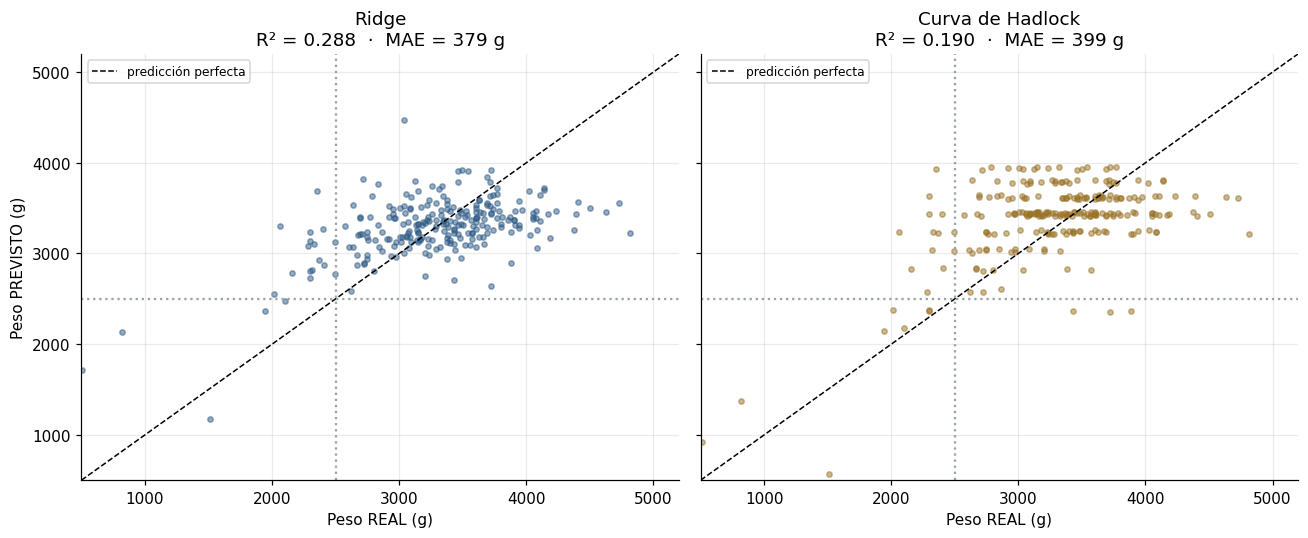

In [21]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, n, c in [(ejes[0], "Ridge", AZUL), (ejes[1], "Curva de Hadlock", OCRE)]:
    pp = pred_peso[n]
    ax.scatter(yp_pru, pp + (np.random.uniform(-25, 25, len(pp)) if n == "Curva de Hadlock" else 0),
               s=12, alpha=0.5, color=c)
    lim = [500, 5200]
    ax.plot(lim, lim, "k--", lw=1, label="predicción perfecta")
    ax.axvline(2500, color=GRIS, ls=":"); ax.axhline(2500, color=GRIS, ls=":")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{n}\nR² = {r2_score(yp_pru, pp):.3f}  ·  MAE = {mean_absolute_error(yp_pru, pp):.0f} g")
    ax.set_xlabel("Peso REAL (g)")
    ax.legend(loc="upper left", fontsize=8)
ejes[0].set_ylabel("Peso PREVISTO (g)")
plt.tight_layout()
plt.show()

**Error medio de cada modelo** (validación cruzada, con su variación).

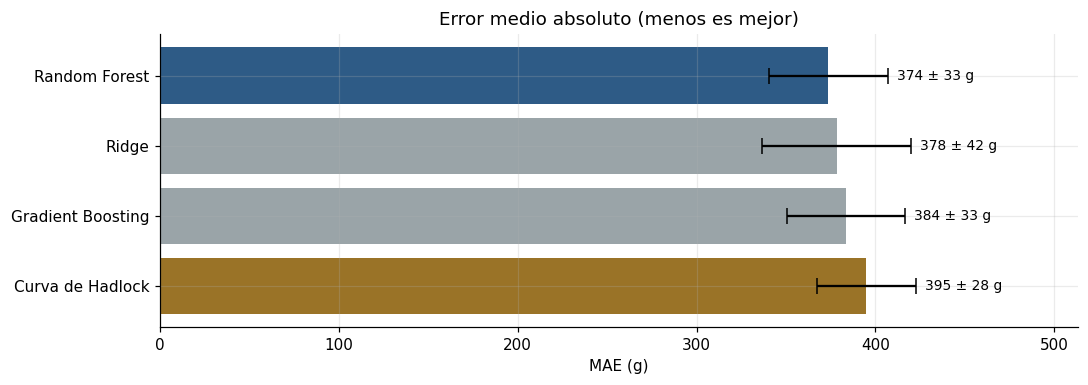

In [22]:
r = cv.sort_values("media")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(r.index, r["media"], xerr=r["desviación"], capsize=5,
        color=[AZUL if n == mejor else OCRE if n == "Curva de Hadlock" else GRIS for n in r.index])
for i, (m, d) in enumerate(zip(r["media"], r["desviación"])):
    ax.text(m + d + 5, i, f"{m:.0f} ± {d:.0f} g", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, r["media"].max() * 1.3)
ax.set_title("Error medio absoluto (menos es mejor)")
ax.set_xlabel("MAE (g)")
plt.tight_layout()
plt.show()

**Curva ROC.** Muestra cuántos bebés de bajo peso se detectan (eje vertical)
según cuántas falsas alarmas se acepten (eje horizontal). El punto marcado es el
umbral elegido.

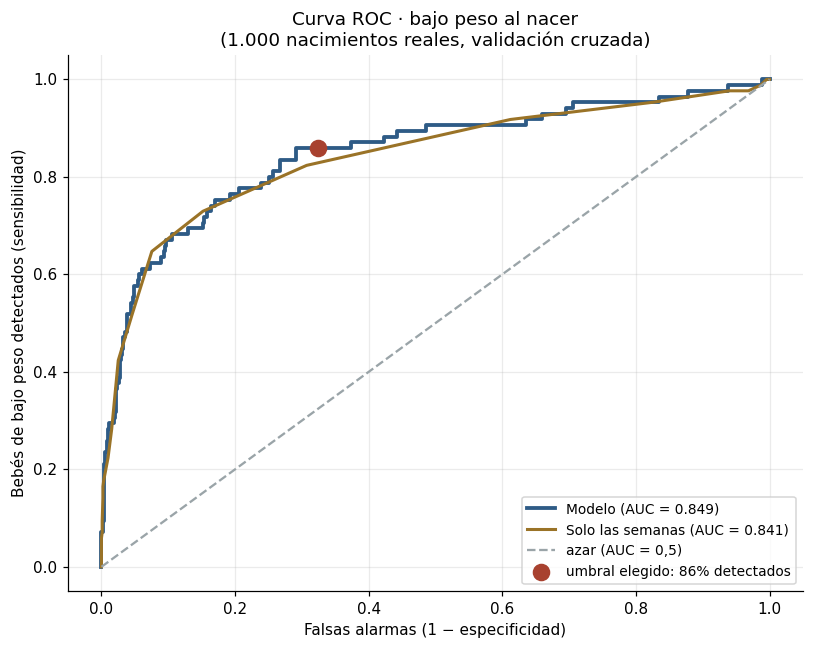

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 6))
fpr, tpr, _ = roc_curve(y_bajo, prob_cv)
auc_modelo = roc_auc_score(y_bajo, prob_cv)
ax.plot(fpr, tpr, color=AZUL, lw=2.5, label=f"Modelo (AUC = {auc_modelo:.3f})")

puntos_sem = -df["semanas_gestacion"]
f2, t2, _ = roc_curve(y_bajo, puntos_sem)
auc_sem = roc_auc_score(y_bajo, puntos_sem)
ax.plot(f2, t2, color=OCRE, lw=2, label=f"Solo las semanas (AUC = {auc_sem:.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", label="azar (AUC = 0,5)")

m = clasif.loc["Modelo (logística + umbral)"]
ax.scatter(1 - m["especificidad"], m["sensibilidad"], s=110, color=ROJO, zorder=5,
           label=f"umbral elegido: {m['sensibilidad']:.0%} detectados")
ax.set_title("Curva ROC · bajo peso al nacer\n(1.000 nacimientos reales, validación cruzada)")
ax.set_xlabel("Falsas alarmas (1 − especificidad)")
ax.set_ylabel("Bebés de bajo peso detectados (sensibilidad)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Matriz de confusión del modelo.** La celda que importa es la de los **verdaderos positivos**.

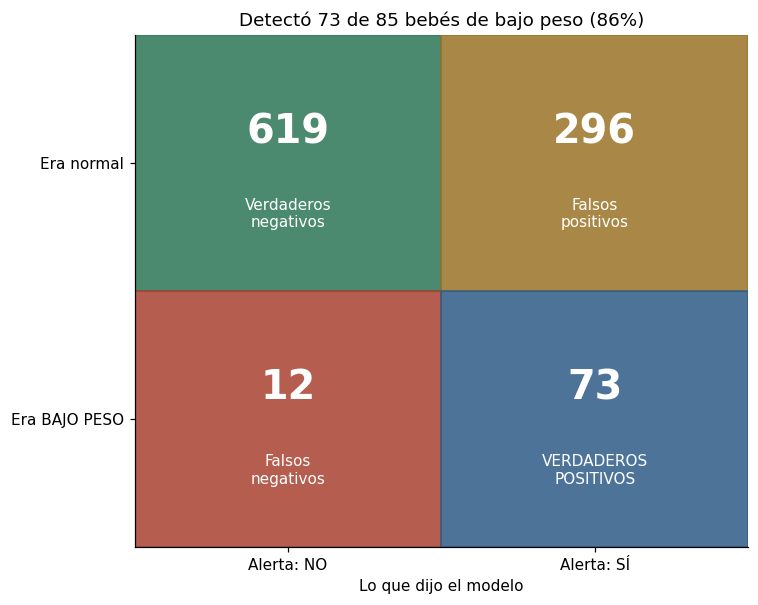

In [24]:
mc = confusion_matrix(y_bajo, alerta_cv, labels=[0, 1])
etiquetas = [["Verdaderos\nnegativos", "Falsos\npositivos"],
             ["Falsos\nnegativos", "VERDADEROS\nPOSITIVOS"]]
colores_celda = [[VERDE, OCRE], [ROJO, AZUL]]

fig, ax = plt.subplots(figsize=(7, 5.6))
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=colores_celda[i][j], alpha=0.85))
        ax.text(j + 0.5, 1.5 - i + 0.12, f"{mc[i, j]}", ha="center", va="center",
                fontsize=26, color="white", fontweight="bold")
        ax.text(j + 0.5, 1.5 - i - 0.2, etiquetas[i][j], ha="center", va="center",
                fontsize=10, color="white")
ax.set_xlim(0, 2); ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5], ["Alerta: NO", "Alerta: SÍ"])
ax.set_yticks([1.5, 0.5], ["Era normal", "Era BAJO PESO"])
ax.set_xlabel("Lo que dijo el modelo")
vp, fn = mc[1, 1], mc[1, 0]
ax.set_title(f"Detectó {vp} de {vp + fn} bebés de bajo peso ({vp / (vp + fn):.0%})")
plt.tight_layout()
plt.show()

**El intercambio: detectar más a cambio de más falsas alarmas.**

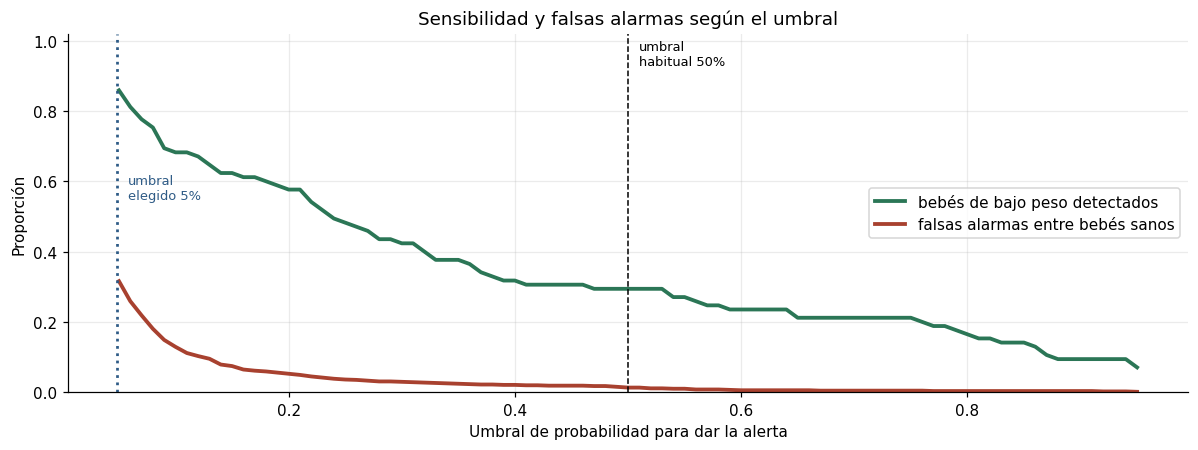

In [25]:
umbrales = np.linspace(0.05, 0.95, 91)
sens = [((prob_cv >= u) & (y_bajo == 1)).sum() / (y_bajo == 1).sum() for u in umbrales]
falsas = [((prob_cv >= u) & (y_bajo == 0)).sum() / (y_bajo == 0).sum() for u in umbrales]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(umbrales, sens, color=VERDE, lw=2.5, label="bebés de bajo peso detectados")
ax.plot(umbrales, falsas, color=ROJO, lw=2.5, label="falsas alarmas entre bebés sanos")
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.text(0.51, 0.93, "umbral\nhabitual 50%", fontsize=8.5)
ax.axvline(umbral, color=AZUL, ls=":", lw=1.8)
ax.text(umbral + 0.01, 0.55, f"umbral\nelegido {umbral:.0%}", fontsize=8.5, color=AZUL)
ax.set_ylim(0, 1.02)
ax.set_title("Sensibilidad y falsas alarmas según el umbral")
ax.set_xlabel("Umbral de probabilidad para dar la alerta")
ax.set_ylabel("Proporción")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

**Qué variables usa más el modelo de regresión.**

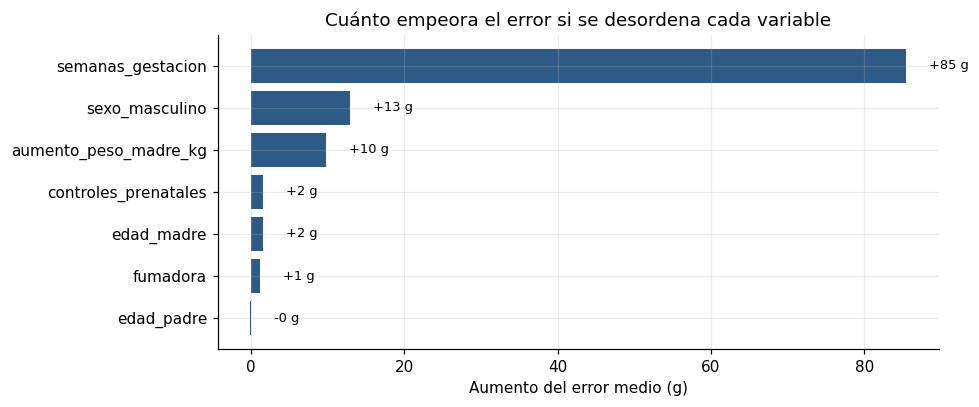

In [26]:
imp = permutation_importance(regresores["Ridge"], X_pru, yp_pru, scoring="neg_mean_absolute_error",
                             n_repeats=20, random_state=SEMILLA, n_jobs=1)
s = pd.Series(imp.importances_mean, index=ENTRADAS).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(s.index, s.values, color=AZUL)
for i, v in enumerate(s.values):
    ax.text(max(v, 0) + 3, i, f"{v:+.0f} g", va="center", fontsize=8.5)
ax.set_title("Cuánto empeora el error si se desordena cada variable")
ax.set_xlabel("Aumento del error medio (g)")
plt.tight_layout()
plt.show()

### 7.5 Resumen

In [27]:
mm = clasif.loc["Modelo (logística + umbral)"]
print("REGRESIÓN (peso en gramos, validación cruzada)")
print(f"  {mejor}: {cv.loc[mejor, 'media']:.0f} g de error medio   ·   "
      f"Curva de Hadlock: {cv.loc['Curva de Hadlock', 'media']:.0f} g")
print(f"  R² de {mejor} en la prueba: {r2_score(yp_pru, pred_peso[mejor]):.3f}")
print(f"  Veredicto frente a Hadlock: "
      f"{'MEJORA REAL' if mejora_real else ('EMPATE' if dif.mean() > 0 else 'PIERDE')}"
      f" ({dif.mean():+.0f} g, gana en {gana} de 5)")
print()
print("CLASIFICACIÓN (bajo peso, 1.000 nacimientos reales)")
print(f"  Verdaderos positivos: {int(mm['verdaderos positivos'])} de "
      f"{int(mm['verdaderos positivos'] + mm['falsos negativos'])} bebés de bajo peso "
      f"({mm['sensibilidad']:.0%})")
print(f"  Falsos negativos (se escaparon): {int(mm['falsos negativos'])}")
print(f"  Falsas alarmas: {int(mm['falsos positivos'])} de "
      f"{int(mm['falsos positivos'] + mm['verdaderos negativos'])} bebés sanos "
      f"({1 - mm['especificidad']:.1%})")
print(f"  Precisión de la alerta: {mm['precisión']:.0%} "
      f"(de cada 100 alertas, unas {mm['precisión'] * 100:.0f} son bebés de bajo peso)")
print(f"  AUC: {auc_modelo:.3f}   (solo con las semanas: {auc_sem:.3f})")
if auc_modelo - auc_sem < 0.02:
    print("  -> Las semanas explican casi todo: los datos de la madre añaden muy poco")
    print("     a la hora de SEPARAR bajo peso de peso normal.")

REGRESIÓN (peso en gramos, validación cruzada)
  Random Forest: 374 g de error medio   ·   Curva de Hadlock: 395 g
  R² de Random Forest en la prueba: 0.322
  Veredicto frente a Hadlock: MEJORA REAL (+21 g, gana en 5 de 5)

CLASIFICACIÓN (bajo peso, 1.000 nacimientos reales)
  Verdaderos positivos: 73 de 85 bebés de bajo peso (86%)
  Falsos negativos (se escaparon): 12
  Falsas alarmas: 296 de 915 bebés sanos (32.3%)
  Precisión de la alerta: 20% (de cada 100 alertas, unas 20 son bebés de bajo peso)
  AUC: 0.849   (solo con las semanas: 0.841)
  -> Las semanas explican casi todo: los datos de la madre añaden muy poco
     a la hora de SEPARAR bajo peso de peso normal.


---
## Cuándo y cómo implementarlo

### De qué se trata

Es una **herramienta de apoyo** para la consulta prenatal. Da dos cosas:

1. **Una estimación del peso al nacer**, al lado de la de Hadlock, para
   comparar.
2. **Una alerta de riesgo de bajo peso**, ajustada para detectar la mayoría de
   los casos aunque cueste algunas revisiones de más.

No diagnostica. Avisa para que la médica mire con más atención.

### En qué módulo entra

| Pieza | Dónde |
|---|---|
| Este notebook y sus datos | `historial/modelo_peso_nacimiento/` — carpeta aparte, para estudiar y presentar |
| La fórmula de Hadlock del sistema | `Backend/ecografias/peso_fetal.py` |
| El modelo dentro del sistema | `Backend/ia_medica/ml/` |
| Comandos para entrenarlo con los datos de la clínica | `python manage.py construir_dataset_peso` · `python manage.py entrenar_modelo_peso` |
| Dónde se vería | Ficha de la ecografía → pestaña **Biometría Fetal** |

Los datos que alimentan el modelo salen de los módulos **`embarazos`**,
**`pacientes`**, **`controles`** y **`ecografias`**, y aprende del peso real que
se registra en **`partos`**.

### Cuándo implementarlo

1. **Con datos de la propia clínica.** Estos nacimientos son reales, pero de
   **Estados Unidos**. En Bolivia, y sobre todo en la altura de La Paz o El Alto,
   los bebés pesan de media algo menos. El modelo tiene que volver a entrenarse
   con partos bolivianos antes de usarse con pacientes.
2. **Con unos 300 partos registrados**, con su edad gestacional, los datos de la
   madre y el peso al nacer. Los comandos del sistema construyen la tabla y
   entrenan solos.
3. **Si vuelve a pasar la evaluación del paso 7** sobre esos datos: que detecte
   la mayoría de los bebés de bajo peso con un número de falsas alarmas que el
   servicio pueda asumir.

### Cómo implementarlo

1. Registrar los partos en el sistema como ya se hace.
2. Ejecutar `construir_dataset_peso` y luego `entrenar_modelo_peso`. El comando
   se niega a guardar un modelo que no mejore lo que ya existe.
3. Mostrar el resultado en la pestaña **Biometría Fetal** con la estimación, la
   de Hadlock al lado, y la alerta de bajo peso.
4. Guardar cada predicción y compararla con el peso real cuando nazca el bebé.
   **Ese es el resultado que vale.**